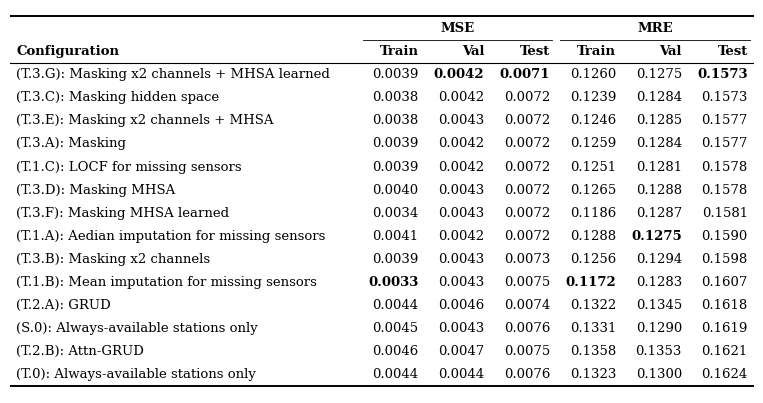

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "pdf.fonttype": 42,
})

path = "outputs/4-RUN_results/Run5/dataframe_errors.csv"
df = pd.read_csv(path).sort_values("test-mre").reset_index(drop=True)

num_cols = ["train-mse", "val-mse", "test-mse", "train-mre", "val-mre", "test-mre"]
cols = ["type"] + num_cols
best = df[num_cols].min()

# ---- layout (widths in inches) ----
widths = [4.5] + [0.85] * 6
xs = [sum(widths[:i]) for i in range(len(widths))]
total_w = sum(widths)
row_h = 0.28
n_rows = len(df)
header_rows = 2
fig_h = (n_rows + header_rows) * row_h + 0.5

fig, ax = plt.subplots(figsize=(total_w, fig_h))
ax.set_xlim(0, total_w)
ax.set_ylim(n_rows + header_rows + 0.3, -0.3)
ax.axis("off")

fs = 9.5
pad = 0.08

def put(col, row, text, ha="left", **kw):
    x = xs[col] + (pad if ha == "left" else widths[col] - pad)
    ax.text(x, row + 0.5, text, ha=ha, va="center", fontsize=fs, **kw)

# ---- header ----
ax.text(xs[1] + sum(widths[1:4]) / 2, 0.5, "MSE", ha="center", va="center", fontsize=fs, fontweight="bold")
ax.text(xs[4] + sum(widths[4:7]) / 2, 0.5, "MRE", ha="center", va="center", fontsize=fs, fontweight="bold")
ax.plot([xs[1] + 0.05, xs[4] - 0.05], [1, 1], color="black", lw=0.6)
ax.plot([xs[4] + 0.05, total_w - 0.05], [1, 1], color="black", lw=0.6)

put(0, 1, "Configuration", fontweight="bold")
for i, name in enumerate(["Train", "Val", "Test"] * 2):
    put(1 + i, 1, name, ha="right", fontweight="bold")

# ---- body ----
for r, row in df.iterrows():
    y = r + header_rows
    put(0, y, row["type"])
    for j, c in enumerate(num_cols):
        is_best = row[c] == best[c]
        put(1 + j, y, f"{row[c]:.4f}", ha="right", fontweight="bold" if is_best else "normal")

# ---- three booktabs rules ----
ax.plot([0, total_w], [0, 0], color="black", lw=1.4)
ax.plot([0, total_w], [header_rows, header_rows], color="black", lw=0.8)
ax.plot([0, total_w], [n_rows + header_rows, n_rows + header_rows], color="black", lw=1.4)

fig.savefig("HYDRO_table.png", dpi=300, bbox_inches="tight")
plt.show()

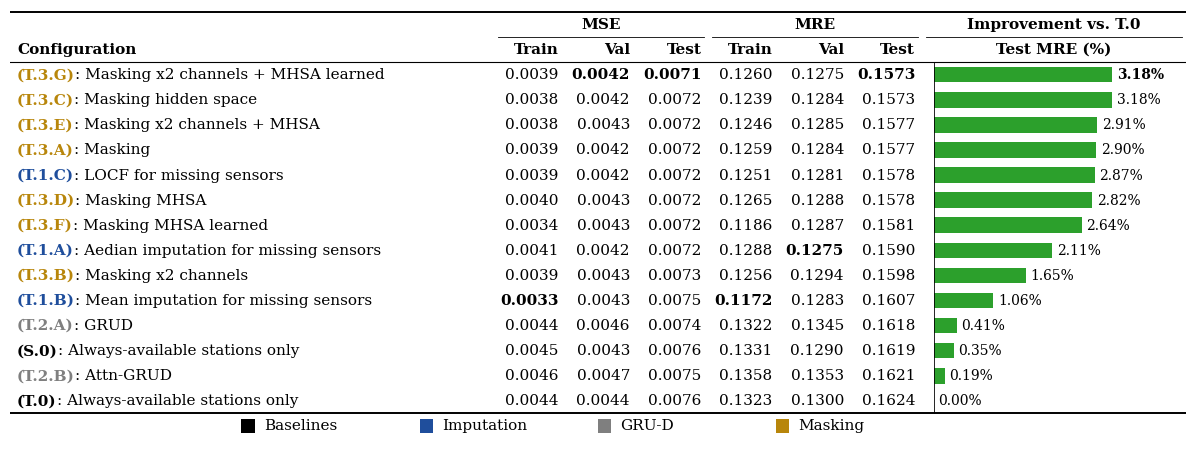

In [4]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "pdf.fonttype": 42,
})

path = "outputs/4-RUN_results/Run5/dataframe_errors.csv"
df = pd.read_csv(path).sort_values("test-mre").reset_index(drop=True)

num_cols = ["train-mse", "val-mse", "test-mse", "train-mre", "val-mre", "test-mre"]
best = df[num_cols].min()

# ---- improvement vs baseline T.0 ----
BASELINE_PREFIX = "(T.0)"
base_mre = df.loc[df["type"].str.startswith(BASELINE_PREFIX), "test-mre"].iloc[0]
df["impr"] = (base_mre - df["test-mre"]) / base_mre * 100
best_impr = df["impr"].max()

# ---- colori per gruppo (palette da paper) ----
C_BASE  = "#000000"   # nero  -> baselines
C_IMPUT = "#1F4E9C"   # blu   -> imputation
C_MASK  = "#B8860B"   # oro   -> masking
C_GRUD  = "#7F7F7F"   # grigio-> GRU-D

GROUP_COLORS = {"0": C_BASE, "1": C_IMPUT, "2": C_GRUD, "3": C_MASK}
LEGEND = [
    ("Baselines", C_BASE),
    ("Imputation", C_IMPUT),
    ("GRU-D", C_GRUD),
    ("Masking", C_MASK),
]
TAG_RE = re.compile(r"^(\([A-Za-z]\.(\d)(?:\.[A-Za-z0-9]+)?\))(.*)$")

# ---- font ----
fs = 11                                # <-- dimensione base del testo
fs_small = fs - 1                      # etichette % delle barre

# ---- layout (widths in inches) ----
first_col_w = 6.25
num_col_w = 0.92
bar_col_w = 3.4
widths = [first_col_w] + [num_col_w] * 6 + [bar_col_w]
xs = [sum(widths[:i]) for i in range(len(widths))]
total_w = sum(widths)
row_h = 0.32
n_rows = len(df)
header_rows = 2
legend_rows = 1.0
fig_h = (n_rows + header_rows + legend_rows + 0.2) * row_h + 0.1

fig, ax = plt.subplots(figsize=(total_w, fig_h))
ax.set_xlim(0, total_w)
ax.set_ylim(n_rows + header_rows + legend_rows + 0.1, -0.1)
ax.axis("off")

pad = 0.09

def put(col, row, text, ha="left", **kw):
    x = xs[col] + (pad if ha == "left" else widths[col] - pad)
    ax.text(x, row + 0.5, text, ha=ha, va="center", fontsize=fs, **kw)

def put_label(row, text):
    """Scrive l'etichetta con il tag (T.x.y) colorato e il resto in nero."""
    m = TAG_RE.match(text)
    if not m:
        put(0, row, text)
        return
    tag, group, rest = m.groups()
    color = GROUP_COLORS.get(group, "black")
    t = ax.text(xs[0] + pad, row + 0.5, tag, ha="left", va="center",
                fontsize=fs, color=color, fontweight="bold")
    bb = t.get_window_extent(renderer=fig.canvas.get_renderer())
    x1 = ax.transData.inverted().transform((bb.x1, bb.y0))[0]
    ax.text(x1, row + 0.5, rest, ha="left", va="center", fontsize=fs)

# ---- header ----
ax.text(xs[1] + sum(widths[1:4]) / 2, 0.5, "MSE", ha="center", va="center", fontsize=fs, fontweight="bold")
ax.text(xs[4] + sum(widths[4:7]) / 2, 0.5, "MRE", ha="center", va="center", fontsize=fs, fontweight="bold")
ax.text(xs[7] + widths[7] / 2, 0.5, "Improvement vs. T.0", ha="center", va="center", fontsize=fs, fontweight="bold")
ax.plot([xs[1] + 0.05, xs[4] - 0.05], [1, 1], color="black", lw=0.6)
ax.plot([xs[4] + 0.05, xs[7] - 0.05], [1, 1], color="black", lw=0.6)
ax.plot([xs[7] + 0.05, total_w - 0.05], [1, 1], color="black", lw=0.6)

put(0, 1, "Configuration", fontweight="bold")
for i, name in enumerate(["Train", "Val", "Test"] * 2):
    put(1 + i, 1, name, ha="right", fontweight="bold")
ax.text(xs[7] + widths[7] / 2, 1.5, "Test MRE (%)", ha="center", va="center", fontsize=fs, fontweight="bold")

# ---- bar scale ----
label_w = 0.85
bx0 = xs[7] + 0.15
usable = widths[7] - 0.15 - label_w - 0.1
vmin = min(df["impr"].min(), 0.0)
vmax = max(df["impr"].max(), 1e-9)
scale = usable / (vmax - vmin)
zero_x = bx0 + (-vmin) * scale
bar_h = 0.62

# ---- body ----
for r, row in df.iterrows():
    y = r + header_rows
    put_label(y, row["type"])
    for j, c in enumerate(num_cols):
        is_best = row[c] == best[c]
        put(1 + j, y, f"{row[c]:.4f}", ha="right", fontweight="bold" if is_best else "normal")

    v = row["impr"]
    w = v * scale
    ax.add_patch(Rectangle((zero_x if v >= 0 else zero_x + w, y + (1 - bar_h) / 2),
                           abs(w), bar_h, facecolor="#2ca02c", edgecolor="none"))

    weight = "bold" if np.isclose(v, best_impr) else "normal"
    if v >= 0:
        ax.text(zero_x + w + 0.06, y + 0.5, f"{v:.2f}%", ha="left", va="center",
                fontsize=fs_small, fontweight=weight)
    else:
        ax.text(zero_x + w - 0.06, y + 0.5, f"{v:.2f}%", ha="right", va="center",
                fontsize=fs_small, fontweight=weight)

ax.plot([zero_x, zero_x], [header_rows, n_rows + header_rows], color="black", lw=0.6)

# ---- three booktabs rules ----
ax.plot([0, total_w], [0, 0], color="black", lw=1.4)
ax.plot([0, total_w], [header_rows, header_rows], color="black", lw=0.8)
ax.plot([0, total_w], [n_rows + header_rows, n_rows + header_rows], color="black", lw=1.4)

# ---- legenda sotto la tabella ----
ly = n_rows + header_rows + legend_rows / 2
sq = 0.17                                              # lato del quadrato (pollici)
sq_h = sq / row_h                                      # stessa dimensione in unità riga
gap_marker_text = 0.12
entry_w = 2.3
x_start = (total_w - entry_w * len(LEGEND)) / 2        # legenda centrata

for i, (label, color) in enumerate(LEGEND):
    x = x_start + i * entry_w
    ax.add_patch(Rectangle((x, ly - sq_h / 2), sq, sq_h, facecolor=color, edgecolor="none"))
    ax.text(x + sq + gap_marker_text, ly, label, ha="left", va="center", fontsize=fs)

fig.savefig("HYDRO_table.png", dpi=300, bbox_inches="tight", pad_inches=0.03)
plt.show()